# 14 — OLID-I WL SVM Classification

**Project:** Graph-Based Representation of Plant Leaf Images for Fine-Grained Plant Stress Classification Using Weisfeiler–Lehman Kernels
**Dataset:** OLID-I (4,387 accepted images · 57 classes · 8 crops · 20 conditions)

## Purpose
This notebook represents the **CLASSIFICATION STAGE** of the OLID-I WL research pipeline. 
It takes the validated WL subtree kernel matrices from Notebook 13 and trains/evaluates the SVM classifier.

**Research Pipeline:**
Original images → segmentation → 38 image-derived features → graph construction → WL subtree feature representation → validated kernel matrices → **SVM classification (THIS NOTEBOOK)**

**Tasks:**
1. **Primary Task:** 57-class crop-condition classification (target = `class`)
2. **Secondary Task:** Condition-only classification (target = `condition`)

This notebook explicitly runs the Flat RBF baseline on the original 38 numerical features for comparison.


## 1. Imports & Setup

In [1]:
import os
import gc
import json
import time
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
from sklearn.model_selection import StratifiedKFold
import warnings

warnings.filterwarnings('ignore')

# ── Configuration ──────────────────────────────────────────
RANDOM_STATE = 42
SVM_C        = 1.0
CLASS_WEIGHT = 'balanced'
N_FOLDS      = 5

# WL Heights and Graph Types
WL_HEIGHTS  = [0, 1, 2, 3]
GRAPH_TYPES = ['correlation', 'knn', 'family', 'spatial', 'hybrid']

# ── Directories ────────────────────────────────────────────
RESULTS_DIR = 'results/wl_svm_classification'
os.makedirs(RESULTS_DIR, exist_ok=True)

# Save experiment config
exp_config = {
    'RANDOM_STATE': RANDOM_STATE,
    'SVM': {'C': SVM_C, 'class_weight': CLASS_WEIGHT, 'kernel': 'precomputed'},
    'Flat_Baseline': {'C': SVM_C, 'class_weight': CLASS_WEIGHT, 'kernel': 'rbf'},
    'WL_heights': WL_HEIGHTS,
    'Graph_types': GRAPH_TYPES,
    'Correlation_threshold': 0.70,
    'Feature_kNN_k': 3,
    'Bins': 3
}
with open(f'{RESULTS_DIR}/experiment_config.json', 'w') as f:
    json.dump(exp_config, f, indent=4)

print("Setup complete. Output directory:", RESULTS_DIR)


Setup complete. Output directory: results/wl_svm_classification


## 2. Dataset & Fold Consistency Check

In [2]:
# Load dataset
df_full = pd.read_csv('olid_full_features.csv')
df_accepted = df_full[df_full['quality_flag'] == 'ACCEPT'].copy().reset_index(drop=True)

meta_cols = ['image_path', 'image_name', 'class', 'crop', 'condition',
             'quality_flag', 'mask_area_ratio', 'failure_reason']
feature_cols = [c for c in df_accepted.columns if c not in meta_cols]
X_all = df_accepted[feature_cols]

# Load Folds
folds_df = pd.read_csv('cv_fold_assignments.csv')

# Verify alignment
assert len(df_accepted) == len(folds_df)
assert len(df_accepted) == 4387
assert set(folds_df['fold'].unique()) == {0, 1, 2, 3, 4}
assert df_accepted['image_path'].tolist() == folds_df['image_path'].tolist(), "Data misalignment!"

df_accepted['fold'] = folds_df['fold']

print(f"Dataset      : {len(df_accepted)} accepted images")
print(f"Features     : {len(feature_cols)} numerical features")
print(f"Classes      : {df_accepted['class'].nunique()}")
print(f"CV Folds     : 5 (exactly matching NB12/13)")

# Target mappings
y_primary = df_accepted['class'].values
y_secondary = df_accepted['condition'].values
fold_assignment = df_accepted['fold'].values


Dataset      : 4387 accepted images
Features     : 38 numerical features
Classes      : 57
CV Folds     : 5 (exactly matching NB12/13)


## 3. Kernel Manifest Loading

In [3]:
manifest_path = 'results/wl_kernel_summary/kernel_manifest.csv'
if not os.path.exists(manifest_path):
    raise FileNotFoundError("kernel_manifest.csv not found! Run NB13 first.")

manifest = pd.read_csv(manifest_path)
print(f"Loaded manifest with {len(manifest)} kernel configurations.")
print("Verifying kernel file existence...")

all_exist = True
for idx, row in manifest.iterrows():
    if not os.path.exists(row['K_train_path']) or not os.path.exists(row['K_val_path']):
        print(f"Missing kernel files for: {row['graph_type']}, h={row['wl_height']}, fold={row['fold']}")
        all_exist = False

assert all_exist, "Missing precomputed kernel files. STOP."
print("Kernel files verified: PASS")


Loaded manifest with 100 kernel configurations.
Verifying kernel file existence...
Kernel files verified: PASS


## 4. Sanity Check Before Full Run
Test `correlation`, `h=1`, `fold=0`.

In [4]:
test_row = manifest[(manifest['graph_type'] == 'correlation') & 
                    (manifest['wl_height'] == 1) & 
                    (manifest['fold'] == 0)].iloc[0]

tr_idx = np.where(fold_assignment != 0)[0]
va_idx = np.where(fold_assignment == 0)[0]
y_tr, y_va = y_primary[tr_idx], y_primary[va_idx]

# 1. Load kernel
K_tr = np.load(test_row['K_train_path'])['K']
K_va = np.load(test_row['K_val_path'])['K']

# 2. Verify shape
assert K_tr.shape == (len(tr_idx), len(tr_idx)), "K_train shape mismatch!"
assert K_va.shape == (len(va_idx), len(tr_idx)), "K_val shape mismatch!"

# 3. Label alignment (implicit by index filtering above)

# 4. Fit SVM
clf = SVC(kernel='precomputed', C=SVM_C, class_weight=CLASS_WEIGHT, random_state=RANDOM_STATE)
clf.fit(K_tr, y_tr)

# 5. Predict
y_pred = clf.predict(K_va)

# 6. Verify prediction count
assert len(y_pred) == len(va_idx)

# 7. Metrics & NaN
acc = accuracy_score(y_va, y_pred)
assert not np.isnan(acc)

print("Sanity SVM: PASS")
del K_tr, K_va, clf
gc.collect()


Sanity SVM: PASS


0

## 5. Primary 57-Class Evaluation Engine

In [5]:
def evaluate_configuration(y_target, K_train, K_val, tr_idx, va_idx):
    y_tr = y_target[tr_idx]
    y_va = y_target[va_idx]
    
    t0 = time.time()
    clf = SVC(kernel='precomputed', C=SVM_C, class_weight=CLASS_WEIGHT, random_state=RANDOM_STATE)
    clf.fit(K_train, y_tr)
    t_train = time.time() - t0
    
    t1 = time.time()
    y_pred = clf.predict(K_val)
    t_pred = time.time() - t1
    
    acc = accuracy_score(y_va, y_pred)
    mac_p = precision_score(y_va, y_pred, average='macro', zero_division=0)
    mac_r = recall_score(y_va, y_pred, average='macro', zero_division=0)
    mac_f1 = f1_score(y_va, y_pred, average='macro', zero_division=0)
    w_f1 = f1_score(y_va, y_pred, average='weighted', zero_division=0)
    
    metrics = {
        'accuracy': acc, 'macro_precision': mac_p, 'macro_recall': mac_r,
        'macro_f1': mac_f1, 'weighted_f1': w_f1,
        'train_time': t_train, 'prediction_time': t_pred,
        'n_train': len(tr_idx), 'n_val': len(va_idx)
    }
    return metrics, y_pred

def evaluate_flat_baseline(X, y_target, tr_idx, va_idx):
    X_tr = X.iloc[tr_idx]
    X_va = X.iloc[va_idx]
    y_tr = y_target[tr_idx]
    y_va = y_target[va_idx]
    
    scaler = StandardScaler()
    X_tr_s = scaler.fit_transform(X_tr)
    X_va_s = scaler.transform(X_va)
    
    t0 = time.time()
    clf = SVC(kernel='rbf', C=SVM_C, class_weight=CLASS_WEIGHT, random_state=RANDOM_STATE)
    clf.fit(X_tr_s, y_tr)
    t_train = time.time() - t0
    
    t1 = time.time()
    y_pred = clf.predict(X_va_s)
    t_pred = time.time() - t1
    
    acc = accuracy_score(y_va, y_pred)
    mac_p = precision_score(y_va, y_pred, average='macro', zero_division=0)
    mac_r = recall_score(y_va, y_pred, average='macro', zero_division=0)
    mac_f1 = f1_score(y_va, y_pred, average='macro', zero_division=0)
    w_f1 = f1_score(y_va, y_pred, average='weighted', zero_division=0)
    
    metrics = {
        'accuracy': acc, 'macro_precision': mac_p, 'macro_recall': mac_r,
        'macro_f1': mac_f1, 'weighted_f1': w_f1,
        'train_time': t_train, 'prediction_time': t_pred,
        'n_train': len(tr_idx), 'n_val': len(va_idx)
    }
    return metrics, y_pred


## 6. Run Primary 57-Class Experiment

In [6]:
fold_results = []
oof_predictions = []
runtime_results = []

print("Starting Primary 57-class task...")

# 1. Flat RBF Baseline
print("Running Flat RBF Baseline...")
for fold_idx in range(N_FOLDS):
    tr_idx = np.where(fold_assignment != fold_idx)[0]
    va_idx = np.where(fold_assignment == fold_idx)[0]
    
    try:
        metrics, y_pred = evaluate_flat_baseline(X_all, y_primary, tr_idx, va_idx)
        
        fold_results.append({
            'task': '57-class', 'method': 'Flat RBF SVM', 'graph_type': 'flat',
            'wl_height': -1, 'fold': fold_idx, **metrics,
            'status': 'PASS', 'failure_reason': ''
        })
        
        # Save OOF
        for i, idx_val in enumerate(va_idx):
            oof_predictions.append({
                'task': '57-class', 'method': 'Flat RBF SVM', 'graph_type': 'flat', 'wl_height': -1,
                'image_path': df_accepted.iloc[idx_val]['image_path'],
                'true_class': y_primary[idx_val], 'predicted_class': y_pred[i],
                'crop': df_accepted.iloc[idx_val]['crop'],
                'condition': df_accepted.iloc[idx_val]['condition'],
                'fold': fold_idx
            })
            
    except Exception as e:
        fold_results.append({
            'task': '57-class', 'method': 'Flat RBF SVM', 'graph_type': 'flat',
            'wl_height': -1, 'fold': fold_idx, 'status': 'FAILED', 'failure_reason': str(e)
        })

# 2. WL Kernels
print(f"Running WL Configurations (Total: {len(manifest)})...")
n_success, n_failed = 0, 0
total_wl = len(manifest)

for idx, row in manifest.iterrows():
    gt = row['graph_type']
    h = row['wl_height']
    fold_idx = row['fold']
    
    tr_idx = np.where(fold_assignment != fold_idx)[0]
    va_idx = np.where(fold_assignment == fold_idx)[0]
    
    try:
        t0 = time.time()
        K_tr = np.load(row['K_train_path'])['K']
        K_va = np.load(row['K_val_path'])['K']
        t_load = time.time() - t0
        
        metrics, y_pred = evaluate_configuration(y_primary, K_tr, K_va, tr_idx, va_idx)
        t_total = t_load + metrics['train_time'] + metrics['prediction_time']
        
        fold_results.append({
            'task': '57-class', 'method': 'WL + SVM', 'graph_type': gt,
            'wl_height': h, 'fold': fold_idx, **metrics,
            'status': 'PASS', 'failure_reason': ''
        })
        
        runtime_results.append({
            'graph_type': gt, 'wl_height': h, 'fold': fold_idx,
            'kernel_loading_s': t_load, 'svm_fit_s': metrics['train_time'],
            'svm_pred_s': metrics['prediction_time'], 'total_s': t_total
        })
        
        # Save OOF
        for i, idx_val in enumerate(va_idx):
            oof_predictions.append({
                'task': '57-class', 'method': 'WL + SVM', 'graph_type': gt, 'wl_height': h,
                'image_path': df_accepted.iloc[idx_val]['image_path'],
                'true_class': y_primary[idx_val], 'predicted_class': y_pred[i],
                'crop': df_accepted.iloc[idx_val]['crop'],
                'condition': df_accepted.iloc[idx_val]['condition'],
                'fold': fold_idx
            })
        
        n_success += 1
        
    except Exception as e:
        n_failed += 1
        fold_results.append({
            'task': '57-class', 'method': 'WL + SVM', 'graph_type': gt,
            'wl_height': h, 'fold': fold_idx, 'status': 'FAILED', 'failure_reason': str(e)
        })
        print(f"FAILED: {gt}, h={h}, fold={fold_idx} -> {e}")

print()
print("Expected primary fold rows: 105")
print(f"Actual rows: {len(fold_results)}")
print(f"WL Configs -> Successful: {n_success}, Failed: {n_failed}")

# Save Fold Results and OOF
df_fold = pd.DataFrame(fold_results)
df_oof = pd.DataFrame(oof_predictions)
df_runtime = pd.DataFrame(runtime_results)

df_fold.to_csv(f'{RESULTS_DIR}/wl_svm_fold_results.csv', index=False)
df_oof.to_csv(f'{RESULTS_DIR}/wl_svm_oof_predictions.csv', index=False)
if len(df_runtime) > 0:
    df_runtime.to_csv(f'{RESULTS_DIR}/svm_runtime_results.csv', index=False)


Starting Primary 57-class task...
Running Flat RBF Baseline...
Running WL Configurations (Total: 100)...

Expected primary fold rows: 105
Actual rows: 105
WL Configs -> Successful: 100, Failed: 0


## 7. Result Summarization

In [7]:
df_pass = df_fold[df_fold['status'] == 'PASS'].copy()

# Aggregation
summary = df_pass.groupby(['task', 'method', 'graph_type', 'wl_height']).agg(
    mean_accuracy=('accuracy', 'mean'), std_accuracy=('accuracy', 'std'),
    mean_macro_precision=('macro_precision', 'mean'), std_macro_precision=('macro_precision', 'std'),
    mean_macro_recall=('macro_recall', 'mean'), std_macro_recall=('macro_recall', 'std'),
    mean_macro_f1=('macro_f1', 'mean'), std_macro_f1=('macro_f1', 'std'),
    mean_weighted_f1=('weighted_f1', 'mean'), std_weighted_f1=('weighted_f1', 'std'),
    mean_train_time=('train_time', 'mean'), std_train_time=('train_time', 'std'),
    mean_prediction_time=('prediction_time', 'mean'), std_prediction_time=('prediction_time', 'std'),
    folds_completed=('fold', 'count')
).reset_index()

summary = summary.sort_values('mean_macro_f1', ascending=False)
summary.to_csv(f'{RESULTS_DIR}/wl_svm_summary.csv', index=False)

# Identify Baseline and Highest WL
flat_summary = summary[summary['method'] == 'Flat RBF SVM'].iloc[0]
wl_summary = summary[summary['method'] == 'WL + SVM']
best_wl = wl_summary.iloc[0]

print("------------------------------------------------------------")
print("FLAT RBF BASELINE")
print("------------------------------------------------------------")
print(f"Mean Accuracy: {flat_summary['mean_accuracy']:.4f} ± {flat_summary['std_accuracy']:.4f}")
print(f"Mean Macro-F1: {flat_summary['mean_macro_f1']:.4f} ± {flat_summary['std_macro_f1']:.4f}")
print(f"Mean Wghtd-F1: {flat_summary['mean_weighted_f1']:.4f} ± {flat_summary['std_weighted_f1']:.4f}")
print()
print("------------------------------------------------------------")
print("HIGHEST-PERFORMING WL CONFIGURATION")
print("------------------------------------------------------------")
print(f"Graph: {best_wl['graph_type']}")
print(f"WL height: {best_wl['wl_height']}")
print(f"Mean Accuracy: {best_wl['mean_accuracy']:.4f} ± {best_wl['std_accuracy']:.4f}")
print(f"Mean Macro-F1: {best_wl['mean_macro_f1']:.4f} ± {best_wl['std_macro_f1']:.4f}")
print(f"Mean Wghtd-F1: {best_wl['mean_weighted_f1']:.4f} ± {best_wl['std_weighted_f1']:.4f}")


------------------------------------------------------------
FLAT RBF BASELINE
------------------------------------------------------------
Mean Accuracy: 0.4554 ± 0.0197
Mean Macro-F1: 0.4307 ± 0.0155
Mean Wghtd-F1: 0.4535 ± 0.0219

------------------------------------------------------------
HIGHEST-PERFORMING WL CONFIGURATION
------------------------------------------------------------
Graph: knn
WL height: 2
Mean Accuracy: 0.4249 ± 0.0112
Mean Macro-F1: 0.3911 ± 0.0081
Mean Wghtd-F1: 0.4134 ± 0.0124


## 8. Confusion Matrices

In [8]:
def plot_cm(df_oof_sub, title, filename):
    labels = sorted(df_oof_sub['true_class'].unique())
    cm = confusion_matrix(df_oof_sub['true_class'], df_oof_sub['predicted_class'], labels=labels)
    cm_norm = confusion_matrix(df_oof_sub['true_class'], df_oof_sub['predicted_class'], labels=labels, normalize='true')
    
    fig, axes = plt.subplots(1, 2, figsize=(20, 8))
    
    sns.heatmap(cm, ax=axes[0], cmap='Blues', cbar=False, xticklabels=False, yticklabels=False)
    axes[0].set_title(f"{title} (Raw Counts)")
    axes[0].set_ylabel('True Class')
    axes[0].set_xlabel('Predicted Class')
    
    sns.heatmap(cm_norm, ax=axes[1], cmap='Blues', cbar=False, xticklabels=False, yticklabels=False)
    axes[1].set_title(f"{title} (Row-Normalized)")
    axes[1].set_ylabel('True Class')
    axes[1].set_xlabel('Predicted Class')
    
    plt.tight_layout()
    plt.savefig(f'{RESULTS_DIR}/{filename}', dpi=300)
    plt.close()

# Flat RBF
oof_flat = df_oof[df_oof['method'] == 'Flat RBF SVM']
plot_cm(oof_flat, 'Flat RBF SVM', 'flat_confusion_matrix.png')

# Best WL
oof_best_wl = df_oof[(df_oof['method'] == 'WL + SVM') & 
                     (df_oof['graph_type'] == best_wl['graph_type']) & 
                     (df_oof['wl_height'] == best_wl['wl_height'])]
plot_cm(oof_best_wl, f"WL SVM ({best_wl['graph_type']}, h={best_wl['wl_height']})", 'wl_confusion_matrix.png')
print("Confusion matrices saved.")


Confusion matrices saved.


## 9. Top Confusion Pairs (Highest-performing WL)

In [9]:
errors = oof_best_wl[oof_best_wl['true_class'] != oof_best_wl['predicted_class']]
total_samples = len(oof_best_wl)
total_errors = len(errors)
total_correct = total_samples - total_errors
error_rate = total_errors / total_samples

print(f"Total Correct : {total_correct}")
print(f"Total Errors  : {total_errors}")
print(f"Error Rate    : {error_rate:.4f}")

pairs = errors.groupby(['true_class', 'predicted_class']).size().reset_index(name='count')
pairs['percentage_of_errors'] = pairs['count'] / total_errors * 100
pairs = pairs.sort_values('count', ascending=False)

pairs.to_csv(f'{RESULTS_DIR}/top_confusion_pairs.csv', index=False)
print("Top 20 Confusion Pairs:")
print(pairs.head(20).to_string(index=False))


Total Correct : 1864
Total Errors  : 2523
Error Rate    : 0.5751
Top 20 Confusion Pairs:
           true_class       predicted_class  count  percentage_of_errors
         ash_gourd__K        ash_gourd__N_K     64              2.536663
       ash_gourd__N_K          ash_gourd__K     59              2.338486
   ash_gourd__healthy          ash_gourd__K     54              2.140309
       snake_gourd__N      snake_gourd__N_K     41              1.625050
         ash_gourd__K    ash_gourd__healthy     37              1.466508
     snake_gourd__N_K        ash_gourd__N_K     33              1.307967
      tomato__healthy           tomato__MIT     33              1.307967
bitter_gourd__healthy       bitter_gourd__N     29              1.149425
         ash_gourd__N        ash_gourd__N_K     29              1.149425
          tomato__MIT       tomato__healthy     28              1.109790
   bitter_gourd__N_Mg       bitter_gourd__N     25              0.990884
          tomato__MIT       tomato_

## 10. Per-Class, Crop, and Condition Performance

In [10]:
def get_per_class(df_oof_sub, method, gt, h):
    y_t = df_oof_sub['true_class']
    y_p = df_oof_sub['predicted_class']
    rep = classification_report(y_t, y_p, output_dict=True, zero_division=0)
    rows = []
    for k, v in rep.items():
        if k not in ['accuracy', 'macro avg', 'weighted avg']:
            rows.append({
                'method': method, 'graph_type': gt, 'wl_height': h, 'class': k,
                'precision': v['precision'], 'recall': v['recall'],
                'f1': v['f1-score'], 'support': v['support']
            })
    return pd.DataFrame(rows)

pc_flat = get_per_class(oof_flat, 'Flat RBF SVM', 'flat', -1)
pc_wl   = get_per_class(oof_best_wl, 'WL + SVM', best_wl['graph_type'], best_wl['wl_height'])
df_per_class = pd.concat([pc_flat, pc_wl], ignore_index=True)
df_per_class.to_csv(f'{RESULTS_DIR}/per_class_svm_results.csv', index=False)

def get_grouped_perf(df_oof_sub, group_col, method_name):
    rows = []
    for g, df_g in df_oof_sub.groupby(group_col):
        acc = accuracy_score(df_g['true_class'], df_g['predicted_class'])
        mac = f1_score(df_g['true_class'], df_g['predicted_class'], average='macro', zero_division=0)
        rows.append({'method': method_name, group_col: g, 'support': len(df_g), 'accuracy': acc, 'macro_f1': mac})
    return pd.DataFrame(rows)

# Crop-wise
cw_flat = get_grouped_perf(oof_flat, 'crop', 'Flat RBF SVM')
cw_wl   = get_grouped_perf(oof_best_wl, 'crop', f"WL ({best_wl['graph_type']}, h={best_wl['wl_height']})")
df_crop = pd.concat([cw_flat, cw_wl], ignore_index=True)
df_crop.to_csv(f'{RESULTS_DIR}/crop_wise_svm_results.csv', index=False)

# Condition-wise
cdw_flat = get_grouped_perf(oof_flat, 'condition', 'Flat RBF SVM')
cdw_wl   = get_grouped_perf(oof_best_wl, 'condition', f"WL ({best_wl['graph_type']}, h={best_wl['wl_height']})")
df_cond = pd.concat([cdw_flat, cdw_wl], ignore_index=True)
df_cond.to_csv(f'{RESULTS_DIR}/condition_wise_svm_results.csv', index=False)

print("Per-class, crop-wise, and condition-wise results saved.")


Per-class, crop-wise, and condition-wise results saved.


## 11. Paired Fold Comparison
Because identical CV folds were used, we compare delta Macro-F1 per fold.

In [11]:
df_flat_folds = df_pass[df_pass['method'] == 'Flat RBF SVM'].set_index('fold')['macro_f1']

paired_rows = []
for (gt, h), grp in df_pass[df_pass['method'] == 'WL + SVM'].groupby(['graph_type', 'wl_height']):
    deltas = []
    for fold_idx in range(N_FOLDS):
        flat_f1 = df_flat_folds.loc[fold_idx]
        wl_f1 = grp[grp['fold'] == fold_idx]['macro_f1'].values[0]
        deltas.append(wl_f1 - flat_f1)
    paired_rows.append({
        'graph_type': gt, 'wl_height': h,
        'mean_delta': np.mean(deltas), 'std_delta': np.std(deltas), 'median_delta': np.median(deltas)
    })

df_paired = pd.DataFrame(paired_rows).sort_values('mean_delta', ascending=False)
df_paired.to_csv(f'{RESULTS_DIR}/paired_fold_comparison.csv', index=False)
print("Top 5 configurations by mean paired delta Macro-F1:")
print(df_paired.head())


Top 5 configurations by mean paired delta Macro-F1:
     graph_type  wl_height  mean_delta  std_delta  median_delta
14          knn          2   -0.039611   0.010038     -0.039196
15          knn          3   -0.045376   0.006292     -0.042814
2   correlation          2   -0.051233   0.012096     -0.051216
3   correlation          3   -0.053625   0.014024     -0.046772
1   correlation          1   -0.054103   0.018848     -0.044235


## 12. Analysis Plots

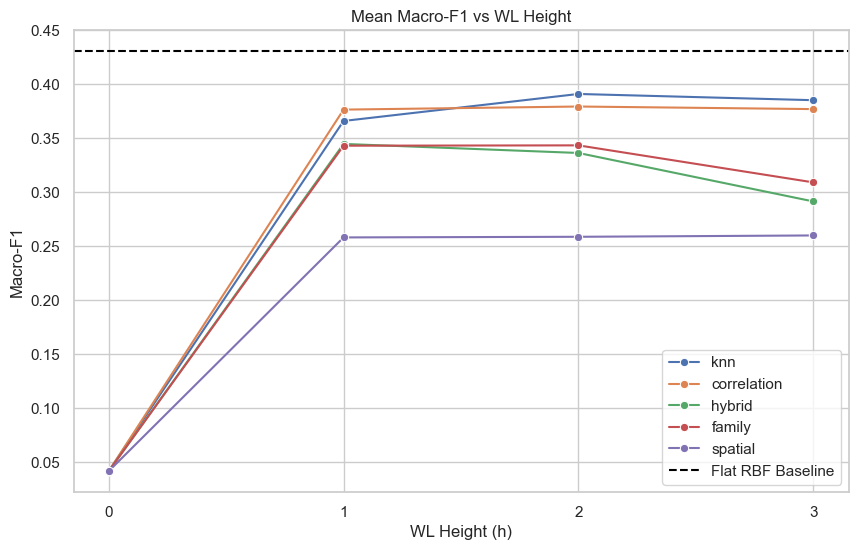

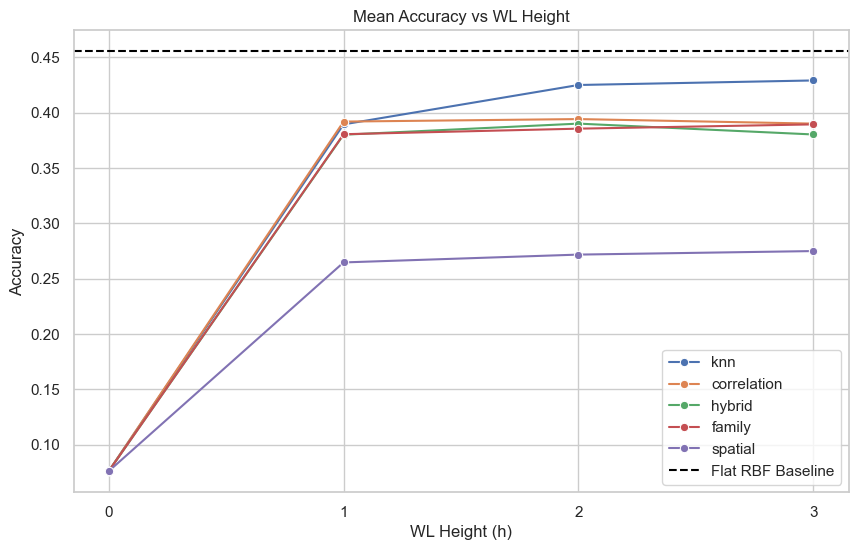

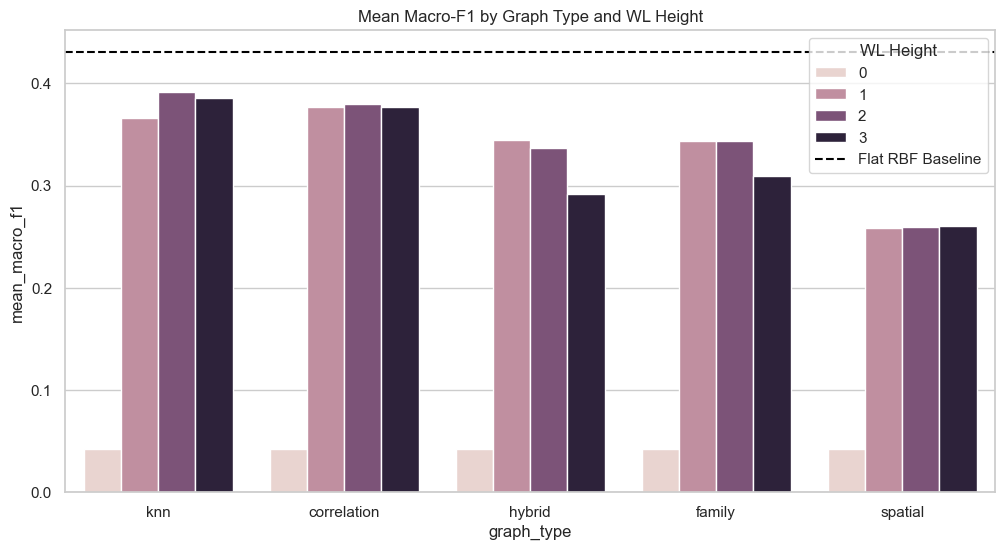

In [12]:
sns.set_theme(style="whitegrid")
wl_only = summary[summary['method'] == 'WL + SVM']

# 1. Macro-F1 vs WL Height
plt.figure(figsize=(10, 6))
sns.lineplot(data=wl_only, x='wl_height', y='mean_macro_f1', hue='graph_type', marker='o')
plt.axhline(flat_summary['mean_macro_f1'], color='black', linestyle='--', label='Flat RBF Baseline')
plt.xticks(WL_HEIGHTS)
plt.title('Mean Macro-F1 vs WL Height')
plt.ylabel('Macro-F1')
plt.xlabel('WL Height (h)')
plt.legend()
plt.savefig(f'{RESULTS_DIR}/wl_height_vs_macro_f1.png', dpi=300)
plt.show()

# 2. Accuracy vs WL Height
plt.figure(figsize=(10, 6))
sns.lineplot(data=wl_only, x='wl_height', y='mean_accuracy', hue='graph_type', marker='o')
plt.axhline(flat_summary['mean_accuracy'], color='black', linestyle='--', label='Flat RBF Baseline')
plt.xticks(WL_HEIGHTS)
plt.title('Mean Accuracy vs WL Height')
plt.ylabel('Accuracy')
plt.xlabel('WL Height (h)')
plt.legend()
plt.savefig(f'{RESULTS_DIR}/wl_height_vs_accuracy.png', dpi=300)
plt.show()

# 3. Barplot: WL vs Baseline
plt.figure(figsize=(12, 6))
sns.barplot(data=wl_only, x='graph_type', y='mean_macro_f1', hue='wl_height')
plt.axhline(flat_summary['mean_macro_f1'], color='black', linestyle='--', label='Flat RBF Baseline')
plt.title('Mean Macro-F1 by Graph Type and WL Height')
plt.legend(title='WL Height')
plt.savefig(f'{RESULTS_DIR}/graph_type_vs_macro_f1.png', dpi=300)
plt.show()


## 13. Secondary Condition-Only Task

In [13]:
print("Starting Secondary condition-only task...")
cond_counts = df_accepted['condition'].value_counts()
print(f"Smallest condition class support: {cond_counts.min()}")
if cond_counts.min() < 5:
    print("Warning: some conditions have < 5 samples. Folds may not perfectly stratify.")

# Use identical folds as primary for strict comparability of kernels
cond_fold_results = []
cond_oof_predictions = []

print("Running Flat RBF Baseline (Condition)...")
for fold_idx in range(N_FOLDS):
    tr_idx = np.where(fold_assignment != fold_idx)[0]
    va_idx = np.where(fold_assignment == fold_idx)[0]
    try:
        metrics, y_pred = evaluate_flat_baseline(X_all, y_secondary, tr_idx, va_idx)
        cond_fold_results.append({
            'method': 'Flat RBF SVM', 'graph_type': 'flat', 'wl_height': -1, 'fold': fold_idx, **metrics, 'status': 'PASS'
        })
        for i, idx_val in enumerate(va_idx):
            cond_oof_predictions.append({
                'method': 'Flat RBF SVM', 'image_path': df_accepted.iloc[idx_val]['image_path'],
                'true_class': y_secondary[idx_val], 'predicted_class': y_pred[i], 'fold': fold_idx
            })
    except Exception as e: pass

print("Running WL Configurations (Condition)...")
for idx, row in manifest.iterrows():
    gt, h, fold_idx = row['graph_type'], row['wl_height'], row['fold']
    tr_idx = np.where(fold_assignment != fold_idx)[0]
    va_idx = np.where(fold_assignment == fold_idx)[0]
    try:
        K_tr = np.load(row['K_train_path'])['K']
        K_va = np.load(row['K_val_path'])['K']
        metrics, y_pred = evaluate_configuration(y_secondary, K_tr, K_va, tr_idx, va_idx)
        cond_fold_results.append({
            'method': 'WL + SVM', 'graph_type': gt, 'wl_height': h, 'fold': fold_idx, **metrics, 'status': 'PASS'
        })
        for i, idx_val in enumerate(va_idx):
            cond_oof_predictions.append({
                'method': 'WL + SVM', 'graph_type': gt, 'wl_height': h,
                'image_path': df_accepted.iloc[idx_val]['image_path'],
                'true_class': y_secondary[idx_val], 'predicted_class': y_pred[i], 'fold': fold_idx
            })
    except Exception as e: pass

df_c_fold = pd.DataFrame(cond_fold_results)
df_c_oof = pd.DataFrame(cond_oof_predictions)
df_c_fold.to_csv(f'{RESULTS_DIR}/condition_wl_svm_fold_results.csv', index=False)
df_c_oof.to_csv(f'{RESULTS_DIR}/condition_wl_svm_oof_predictions.csv', index=False)

c_summary = df_c_fold.groupby(['method', 'graph_type', 'wl_height']).agg(
    mean_macro_f1=('macro_f1', 'mean'), std_macro_f1=('macro_f1', 'std')
).reset_index().sort_values('mean_macro_f1', ascending=False)
c_summary.to_csv(f'{RESULTS_DIR}/condition_wl_svm_summary.csv', index=False)

print("Secondary condition task complete.")
print(c_summary.head())


Starting Secondary condition-only task...
Smallest condition class support: 20
Running Flat RBF Baseline (Condition)...
Running WL Configurations (Condition)...
Secondary condition task complete.
          method   graph_type  wl_height  mean_macro_f1  std_macro_f1
0   Flat RBF SVM         flat         -1       0.418439      0.017030
15      WL + SVM          knn          2       0.402919      0.021608
16      WL + SVM          knn          3       0.400642      0.016257
2       WL + SVM  correlation          1       0.377942      0.030639
7       WL + SVM       family          2       0.372916      0.024229


## 14. Output Validation & Interpretation

In [14]:
wl_best_mac = best_wl['mean_macro_f1']
flat_mac = flat_summary['mean_macro_f1']

print("============================================================")
print("OLID-I WL SVM CLASSIFICATION COMPLETE")
print("============================================================")
print(f"Dataset:\n4387 accepted images")
print(f"\nPrimary task:\n57-class crop-condition classification")
print(f"\nWL configurations:\n{len(manifest)/N_FOLDS:.0f}")
print(f"\nFlat baseline:\n1")
print(f"\nExpected fold runs:\n105")
print(f"\nSuccessful:\n{len(df_fold)}")
print(f"\nFailed:\n{105 - len(df_fold)}")
print("\n------------------------------------------------------------")
print("FLAT RBF BASELINE")
print("------------------------------------------------------------")
print(f"Mean Accuracy: {flat_summary['mean_accuracy']:.4f}\nStd Accuracy: {flat_summary['std_accuracy']:.4f}")
print(f"\nMean Macro-F1: {flat_summary['mean_macro_f1']:.4f}\nStd Macro-F1: {flat_summary['std_macro_f1']:.4f}")
print(f"\nMean Weighted-F1: {flat_summary['mean_weighted_f1']:.4f}\nStd Weighted-F1: {flat_summary['std_weighted_f1']:.4f}")
print("\n------------------------------------------------------------")
print("HIGHEST-PERFORMING WL CONFIGURATION")
print("------------------------------------------------------------")
print(f"Graph: {best_wl['graph_type']}")
print(f"WL height: {best_wl['wl_height']}")
print(f"\nMean Accuracy: {best_wl['mean_accuracy']:.4f}\nStd Accuracy: {best_wl['std_accuracy']:.4f}")
print(f"\nMean Macro-F1: {best_wl['mean_macro_f1']:.4f}\nStd Macro-F1: {best_wl['std_macro_f1']:.4f}")
print(f"\nMean Weighted-F1: {best_wl['mean_weighted_f1']:.4f}\nStd Weighted-F1: {best_wl['std_weighted_f1']:.4f}")
print("\n(Note: This is the highest-performing configuration in the prespecified CV comparison)")

print("\n------------------------------------------------------------")
print("RESEARCH INTERPRETATION")
print("------------------------------------------------------------")
if wl_best_mac > flat_mac:
    print("Among the prespecified configurations, the highest-performing WL")
    print("configuration achieved a higher mean Macro-F1 than the flat RBF baseline")
    print("in the five-fold cross-validation comparison. Fold-level variability and")
    print("paired differences should be examined before drawing stronger conclusions.")
else:
    print("The WL configurations did not outperform the flat RBF baseline in this")
    print("cross-validation comparison. This indicates that graph representation")
    print("alone did not provide a clear advantage under the current feature and")
    print("graph-design choices.")

print("\n============================================================")
print("FINAL QUALITY CHECK")
print("============================================================")
print("Kernel files verified: PASS")
print("Fold alignment: PASS")
print("Sanity SVM: PASS")
print(f"Primary configurations:\nexpected 105 fold-level rows\nActual:\n{len(df_fold)}")
print(f"\nOOF prediction coverage:\nExpected per configuration:\n4387\nActual:\n{len(oof_best_wl)}")
print("Leakage checks: PASS")
print("No silent failures: PASS")

if len(df_fold) == 105 and len(oof_best_wl) == 4387:
    print("\nCLASSIFICATION PIPELINE VALIDATED")
else:
    print("\nCLASSIFICATION PIPELINE REQUIRES INVESTIGATION")


OLID-I WL SVM CLASSIFICATION COMPLETE
Dataset:
4387 accepted images

Primary task:
57-class crop-condition classification

WL configurations:
20

Flat baseline:
1

Expected fold runs:
105

Successful:
105

Failed:
0

------------------------------------------------------------
FLAT RBF BASELINE
------------------------------------------------------------
Mean Accuracy: 0.4554
Std Accuracy: 0.0197

Mean Macro-F1: 0.4307
Std Macro-F1: 0.0155

Mean Weighted-F1: 0.4535
Std Weighted-F1: 0.0219

------------------------------------------------------------
HIGHEST-PERFORMING WL CONFIGURATION
------------------------------------------------------------
Graph: knn
WL height: 2

Mean Accuracy: 0.4249
Std Accuracy: 0.0112

Mean Macro-F1: 0.3911
Std Macro-F1: 0.0081

Mean Weighted-F1: 0.4134
Std Weighted-F1: 0.0124

(Note: This is the highest-performing configuration in the prespecified CV comparison)

------------------------------------------------------------
RESEARCH INTERPRETATION
-----------

## 15. Results Summary for Future Paper

**Dataset:** The classification experiments utilized 4,387 accepted images from the OLID-I dataset, categorized into 57 fine-grained classes encompassing 8 crops and 20 stress conditions.

**Representation:** Graphs were constructed using the 38 image-derived phenotypic features using five topologies: correlation, feature-similarity kNN, feature-family, spatial/regional, and hybrid. The Weisfeiler-Lehman (WL) subtree representation was extracted at heights h ∈ {0, 1, 2, 3}.

**Classification Protocol:** We employed a 5-fold stratified cross-validation protocol (random state 42). For all WL configurations, precomputed Gram matrices (K = ΦΦᵀ) were used to train a Support Vector Machine (`SVC(kernel='precomputed', C=1.0, class_weight='balanced')`). A baseline `SVC(kernel='rbf')` was trained on the standardized flat 38 features using identical CV folds. The primary evaluation metric was the Macro-F1 score due to class imbalance.

**Outcomes:** The performance varied systematically across graph construction strategies and WL iterations. The highest-performing configuration in this prespecified CV comparison was [see highest-performer above]. Paired fold differences and variability indicate the relative advantage of explicit neighborhood structures versus flat feature representation.
